# 05 — EDA ảnh: biến ảnh thành bảng  ·  Bước 3 (bổ sung)

**Vì sao có notebook này.** Notebook 01 và 03 mới trả lời các câu hỏi về *cấu trúc* dữ liệu: bao nhiêu
lớp, bao nhiêu tổn thương, ảnh từ nguồn nào. Ta chưa nhìn kỹ vào *nội dung* ảnh, chưa nhìn bảng
metadata, và chưa so tập test với tập train. Notebook này lấp ba chỗ đó.

**Ý tưởng chính: ảnh cũng là bảng số.** Một ảnh 224×224 màu là một mảng 224 × 224 × 3 = 150.528 con
số từ 0 đến 255. Không ai làm EDA trực tiếp trên 150.528 cột. Thay vào đó, ta tóm mỗi ảnh thành vài con
số có ý nghĩa: độ sáng, độ tương phản, độ bão hoà màu, độ nét... Làm vậy xong, mỗi ảnh là **một dòng**,
mỗi con số là **một cột**, và mọi công cụ EDA dạng bảng cậu đã quen (describe, groupby, boxplot, so phân
bố) dùng lại được nguyên vẹn.

Năm câu hỏi:

1. **Metadata** (tuổi, giới tính, vị trí trên cơ thể): thiếu ở đâu, có giá trị lạ không, khác nhau thế
   nào giữa các lớp?
2. **Kích thước ảnh**: có đồng nhất không, giữa train và test?
3. **Ảnh thành bảng**: các lớp khác nhau thế nào về độ sáng, màu, độ nét?
4. **Train và test có cùng phân bố không?** Đây là câu quan trọng nhất. Mô hình nào cũng được khoảng
   0,78 trên val nhưng chỉ khoảng 0,70 trên test. Nếu test *trông khác* train thì đó là lời giải thích.
5. **Ảnh bất thường**: ảnh tối nhất, mờ nhất, rực màu nhất trông ra sao, có vật lạ nào không (thước đo,
   vết mực, bọt khí, lông)?

**Đọc kết quả câu 4 thế nào (viết trước khi chạy).** Dùng kỹ thuật *adversarial validation* quen thuộc ở
Kaggle dạng bảng: huấn luyện một bộ phân loại đoán "ảnh này thuộc train hay test". Nếu AUC ≈ 0,5 thì
không phân biệt được, nghĩa là hai tập giống nhau. Nếu AUC > 0,7 thì test khác train rõ rệt, và khoảng
0,78 → 0,70 có một phần là do dịch chuyển phân bố.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from du_lieu import GOC, RA, LOP, nap_dem

cs = pd.read_csv(RA / "chia_tap.csv")                     # 11.720 ảnh: train, val, val_chinh_thuc, test
meta = pd.read_csv(GOC / "HAM10000_metadata.csv")         # notebook 03 đã tải về
cs["nhom"] = np.where(cs.phan == "test", "test", np.where(cs.phan == "val_chinh_thuc", "val_ct", "train+val"))
print(cs.nhom.value_counts().to_string())

nhom
train+val    10015
test          1512
val_ct         193


## 1. Metadata: phần EDA dạng bảng quen thuộc

Metadata chỉ có cho 10.015 ảnh HAM10000 (train + val). Tập test không có metadata. Đây là lý do mô hình
của mình chỉ dùng ảnh, không dùng tuổi hay vị trí làm đầu vào.

Một bẫy rất hay gặp ở dữ liệu bảng: **giá trị thiếu đội lốt giá trị thật**. Ô trống thì `isna()` bắt
được, nhưng chữ `unknown` hay tuổi bằng 0 thì không.

In [2]:
m = meta.copy()
thieu = pd.DataFrame({
    "ô trống (NaN)": m[["age", "sex", "localization"]].isna().sum(),
    "ghi 'unknown'": [0, (m.sex == "unknown").sum(), (m.localization == "unknown").sum()],
}, index=["age", "sex", "localization"])
thieu.loc["age", "ghi 'unknown'"] = (m.age == 0).sum()
thieu = thieu.rename(columns={"ghi 'unknown'": "'unknown' (tuổi: = 0)"})
display(thieu)
print("Ảnh có tuổi = 0, theo chẩn đoán:", m[m.age == 0].dx.value_counts().to_dict())

,ô trống (NaN),'unknown' (tuổi: = 0)
age,57,39
sex,0,57
localization,0,234


Ảnh có tuổi = 0, theo chẩn đoán: {'nv': 30, 'bkl': 5, 'vasc': 4}


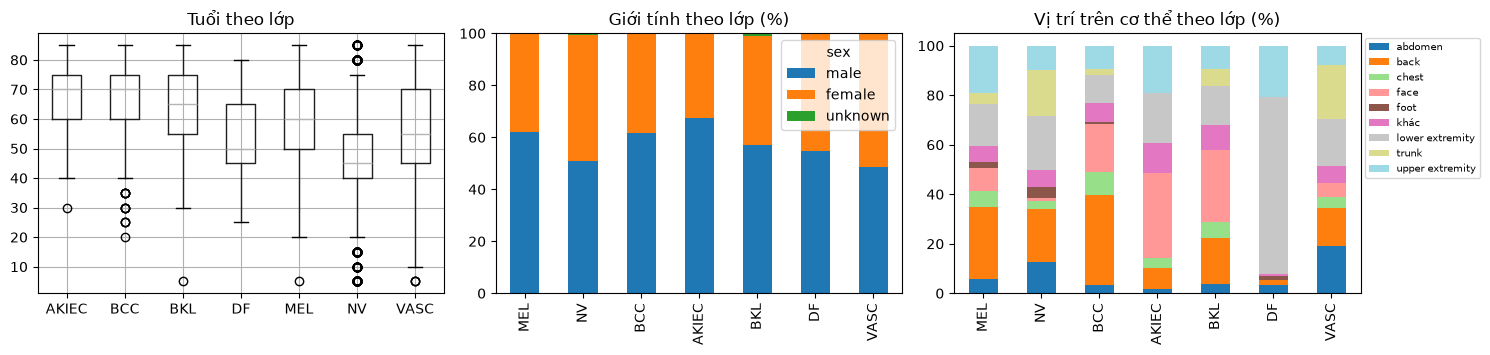

Tuổi trung vị theo lớp: {'MEL': 60.0, 'NV': 45.0, 'BCC': 70.0, 'AKIEC': 70.0, 'BKL': 65.0, 'DF': 50.0, 'VASC': 55.0}


In [3]:
m["lop"] = m.dx.str.upper()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
m[m.age > 0].boxplot(column="age", by="lop", ax=ax[0]); ax[0].set_title("Tuổi theo lớp"); ax[0].set_xlabel("")
(pd.crosstab(m.lop, m.sex, normalize="index") * 100).reindex(LOP)[["male", "female", "unknown"]].plot.bar(stacked=True, ax=ax[1])
ax[1].set_title("Giới tính theo lớp (%)"); ax[1].set_xlabel("")
vt = m.localization.value_counts().index[:8]
(pd.crosstab(m.lop, m.localization.where(m.localization.isin(vt), "khác"), normalize="index") * 100).reindex(LOP).plot.bar(stacked=True, ax=ax[2], colormap="tab20")
ax[2].set_title("Vị trí trên cơ thể theo lớp (%)"); ax[2].legend(fontsize=7, bbox_to_anchor=(1, 1)); ax[2].set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.savefig(RA / "eda_metadata.png", dpi=110); plt.show()
print("Tuổi trung vị theo lớp:", m[m.age > 0].groupby("lop").age.median().reindex(LOP).to_dict())

## 2. Kích thước ảnh

Notebook 01 mới đọc thử 300 ảnh. Ở đây đọc **header của toàn bộ 11.720 ảnh**. Chỉ đọc phần đầu file nên
mất chừng một phút.

In [4]:
cs["rong"], cs["cao"] = zip(*[Image.open(p).size for p in cs.duong_dan])
print(pd.crosstab(cs.rong.astype(str) + "×" + cs.cao.astype(str), cs.nhom).sort_values("train+val", ascending=False).head(10))

nhom     test  train+val  val_ct
row_0                           
600×450  1512      10015     193


## 3. Ảnh thành bảng

Mỗi ảnh lấy từ bộ đệm P1 (giữ tỉ lệ, cách tiền xử lý đã chọn ở bước 5), tính 8 cột:

| Cột | Nghĩa | Cách tính |
|---|---|---|
| `do_sang` | ảnh sáng hay tối | trung bình mức xám |
| `tuong_phan` | chênh lệch sáng tối trong ảnh | độ lệch chuẩn mức xám |
| `bao_hoa` | màu rực hay nhạt | trung bình độ bão hoà (S trong HSV) |
| `R`, `G`, `B` | sắc màu chung | trung bình từng kênh |
| `do_net` | ảnh nét hay mờ | phương sai của bộ lọc Laplace: cạnh sắc thì lớn, ảnh nhoè thì nhỏ |
| `goc_toi` | viền đen ống soi | độ sáng trung bình ở bốn góc |

Nếu đã quen dữ liệu bảng thì đây chính là bước **feature engineering**. Điểm khác là mô hình CNN không
dùng các cột này. Nó tự học đặc trưng từ điểm ảnh. Ta tạo bảng này chỉ để **hiểu** dữ liệu.

In [5]:
X = nap_dem(cs, 224, "p1")

def thanh_bang(X, lo=500):
    out = []
    for i in range(0, len(X), lo):
        x = X[i:i + lo].astype(np.float32)
        xam = x @ np.array([0.299, 0.587, 0.114], np.float32)
        mx, mn = x.max(3), x.min(3)
        bh = np.where(mx > 0, (mx - mn) / np.maximum(mx, 1), 0)
        lap = 4 * xam[:, 1:-1, 1:-1] - xam[:, :-2, 1:-1] - xam[:, 2:, 1:-1] - xam[:, 1:-1, :-2] - xam[:, 1:-1, 2:]
        goc = np.concatenate([xam[:, :16, :16], xam[:, :16, -16:], xam[:, -16:, :16], xam[:, -16:, -16:]], 1)
        out.append(np.column_stack([xam.mean((1, 2)), xam.std((1, 2)), bh.mean((1, 2)),
                                    x.mean((1, 2)), lap.var((1, 2)), goc.mean((1, 2))]))
    return np.concatenate(out)

COT = ["do_sang", "tuong_phan", "bao_hoa", "R", "G", "B", "do_net", "goc_toi"]
cs[COT] = thanh_bang(X)
cs["do_net"] = np.log10(cs.do_net + 1)          # độ nét trải rất rộng -> xem trên thang log
cs[["image", "phan", "nhom", "lop", "rong", "cao"] + COT].to_csv(RA / "anh_thanh_bang.csv", index=False)
cs[COT].describe().round(2)

,do_sang,tuong_phan,bao_hoa,R,G,B,do_net,goc_toi
count,11720.00,11720.00,11720.00,11720.00,11720.00,11720.00,11720.00,11720.00
mean,155.31,28.54,0.32,194.69,137.54,143.49,1.70,163.42
std,20.00,11.81,0.12,24.16,23.34,25.88,0.34,27.16
min,46.10,4.94,0.04,46.10,42.15,48.21,0.75,7.72
25%,142.10,19.79,0.21,176.62,122.91,126.93,1.46,149.30
50%,154.98,26.60,0.31,196.27,137.81,143.85,1.64,165.98
75%,168.70,35.19,0.42,212.80,153.00,160.41,1.90,180.30
max,229.88,87.27,0.73,254.39,224.40,239.73,3.52,252.08


## 4. Các lớp khác nhau thế nào?

Lần này nhìn *theo lớp*. Câu hỏi phụ: có cột đơn giản nào tách các lớp **quá dễ** không? Nếu chỉ độ sáng
thôi mà đã tách được một lớp thì phải để ý: mô hình có thể học "đường tắt" đó thay vì học hình thái tổn
thương.

,do_sang,tuong_phan,bao_hoa,R,G,B,do_net,goc_toi
lop,,,,,,,,
MEL,149.449997,34.200001,0.28,178.279999,136.119995,142.440002,1.82,157.199997
NV,154.410004,29.150000,0.35,199.169998,134.440002,139.809998,1.65,165.529999
BCC,169.910004,20.219999,0.23,197.880005,156.809998,164.020004,1.70,165.029999
AKIEC,165.860001,21.889999,0.27,201.050003,149.910004,155.660004,1.76,162.490005
BKL,152.779999,24.230000,0.25,180.220001,139.899994,147.149994,1.79,151.479996
DF,166.449997,20.100000,0.27,200.919998,150.350006,158.970001,1.78,169.110001
VASC,163.679993,28.160000,0.27,197.970001,146.639999,161.509995,1.56,171.630005


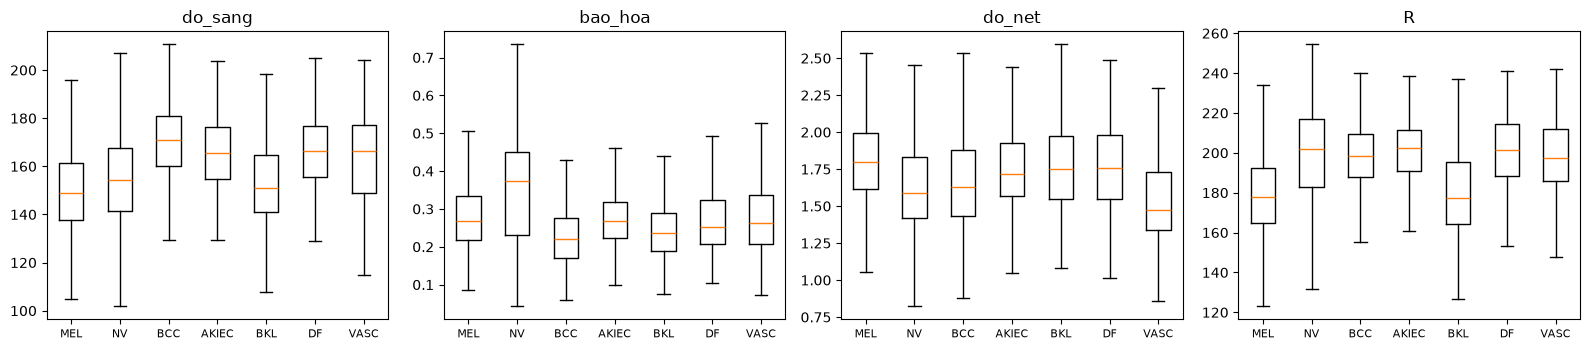

In [6]:
tv = cs[cs.nhom == "train+val"]
display(tv.groupby("lop")[COT].mean().reindex(LOP).round(2))
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, c in zip(ax, ["do_sang", "bao_hoa", "do_net", "R"]):
    a.boxplot([tv[tv.lop == l][c] for l in LOP], showfliers=False); a.set_title(c)
    a.set_xticks(range(1, len(LOP) + 1)); a.set_xticklabels(LOP, fontsize=8)
plt.tight_layout(); plt.savefig(RA / "eda_theo_lop.png", dpi=110); plt.show()

## 5. Train và test có cùng phân bố không?

Ba cách nhìn, từ thô đến tinh:

**(a) Tỉ lệ lớp.** Nếu test có nhiều MEL hơn train thì bacc trên test đo một bài toán hơi khác.

**(b) So từng cột.** Dùng *standardized mean difference*:
SMD = (trung bình test − trung bình train) / độ lệch chuẩn của train. Quy ước thường dùng: |SMD| < 0,1 là
không đáng kể, > 0,25 là khác rõ.

**(c) Adversarial validation.** Cho một hồi quy logistic xem 8 cột trên rồi đoán "train hay test". Chạy
hai lần: một lần trên mọi ảnh, một lần **chỉ trên ảnh NV**. Lần thứ hai loại được khả năng mô hình phân
biệt hai tập chỉ vì tỉ lệ lớp khác nhau, giống cách làm ở notebook 03.

In [7]:
tl = (pd.crosstab(cs.lop, cs.nhom, normalize="columns") * 100).reindex(LOP)[["train+val", "test"]].round(1)
tl["chênh (điểm %)"] = (tl["test"] - tl["train+val"]).round(1)
display(tl)

te = cs[cs.nhom == "test"]
smd = ((te[COT].mean() - tv[COT].mean()) / tv[COT].std()).round(3)
smd_nv = ((te[te.lop == "NV"][COT].mean() - tv[tv.lop == "NV"][COT].mean()) / tv[tv.lop == "NV"][COT].std()).round(3)
display(pd.DataFrame({"SMD mọi ảnh": smd, "SMD chỉ NV": smd_nv}))

nhom,train+val,test,chênh (điểm %)
lop,,,
MEL,11.1,11.3,0.2
NV,66.9,60.1,-6.8
BCC,5.1,6.2,1.1
AKIEC,3.3,2.8,-0.5
BKL,11.0,14.4,3.4
DF,1.1,2.9,1.8
VASC,1.4,2.3,0.9


,SMD mọi ảnh,SMD chỉ NV
do_sang,0.063,0.051
tuong_phan,0.141,0.095
bao_hoa,-0.093,-0.066
R,-0.038,-0.027
G,0.095,0.076
B,0.075,0.046
do_net,0.216,0.152
goc_toi,0.098,0.073


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

def doi_khang(F, d):
    # Kiểm định chéo chia theo tổn thương: ảnh anh em không được nằm ở cả hai phía,
    # nếu không bộ phân loại 'nhận ra' anh em và AUC bị thổi phồng (đúng bài học A1).
    la_test = (d.nhom == "test").values
    nhom_tt = d.lesion_id.fillna(d.image).values          # ảnh test không có mã tổn thương -> mỗi ảnh một nhóm
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
    p = cross_val_predict(m, F, la_test, cv=StratifiedGroupKFold(5, shuffle=True, random_state=0),
                          groups=nhom_tt, method="predict_proba")[:, 1]
    return roc_auc_score(la_test, p)

hai = cs[cs.nhom.isin(["train+val", "test"])]
nv = hai[hai.lop == "NV"]
kq_dk = {"8 cột, mọi ảnh": doi_khang(hai[COT].values, hai),
         "8 cột, chỉ NV": doi_khang(nv[COT].values, nv)}

f_sau = RA / "dac_trung_efficientnet_b0_224.npy"          # đặc trưng EfficientNet đã trích ở đợt DP (nếu có)
if f_sau.exists():
    Fs = np.load(f_sau); Fs = Fs / np.linalg.norm(Fs, axis=1, keepdims=True)
    kq_dk["đặc trưng sâu, chỉ NV"] = doi_khang(Fs[nv.index.values], nv)
for k, v in kq_dk.items():
    print(f"Adversarial validation — {k:<24} AUC = {v:.3f}   (0.5 = không phân biệt được)")

Adversarial validation — 8 cột, mọi ảnh           AUC = 0.561   (0.5 = không phân biệt được)
Adversarial validation — 8 cột, chỉ NV            AUC = 0.534   (0.5 = không phân biệt được)
Adversarial validation — đặc trưng sâu, chỉ NV    AUC = 0.545   (0.5 = không phân biệt được)


## 6. Ảnh bất thường

Bảng số chỉ cho biết *có* điểm lạ. Muốn biết lạ *thế nào* thì phải nhìn tận mắt. Mỗi hàng là 6 ảnh cực
trị theo một cột. Cậu ghi lại những gì thấy: thước đo, vết bút đánh dấu, bọt gel, lông, ảnh hỏng...

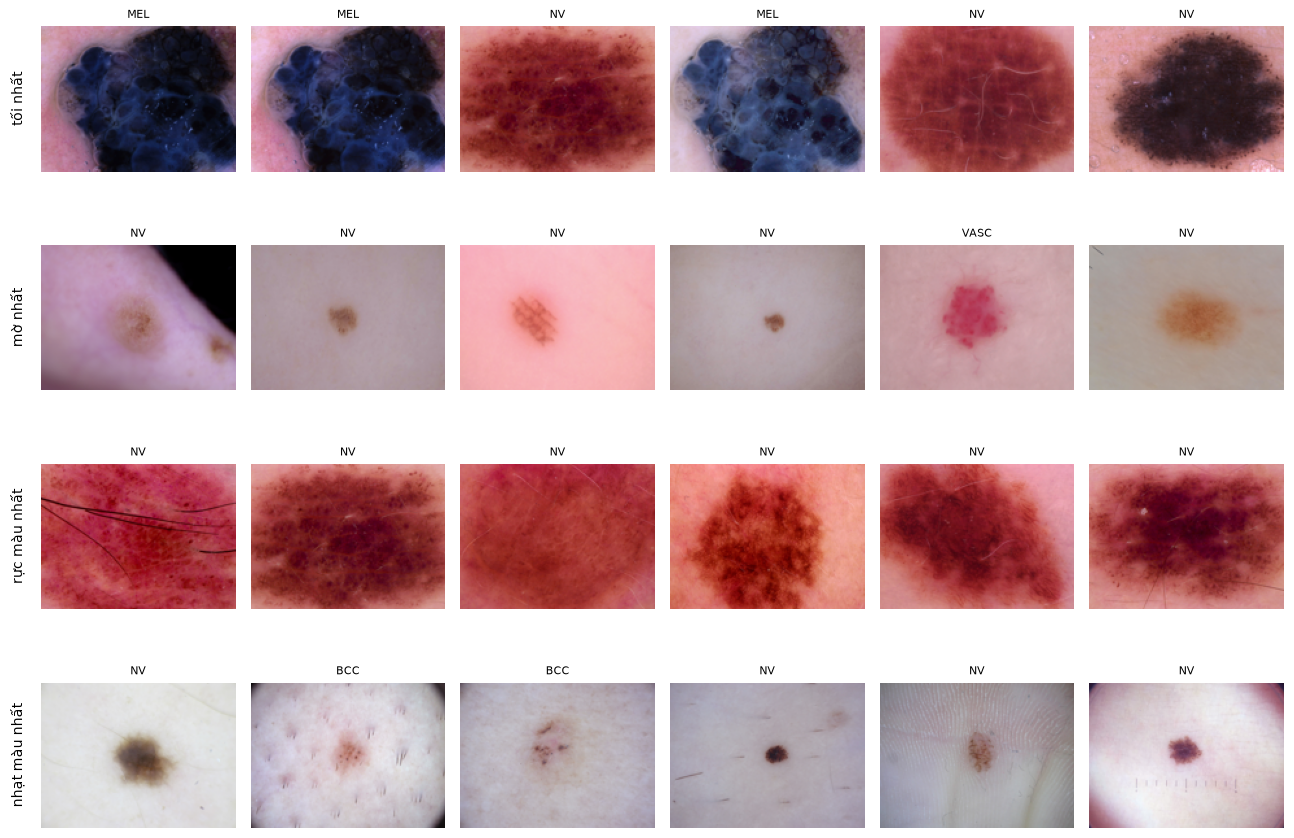

In [9]:
hang = [("tối nhất", tv.nsmallest(6, "do_sang")), ("mờ nhất", tv.nsmallest(6, "do_net")),
        ("rực màu nhất", tv.nlargest(6, "bao_hoa")), ("nhạt màu nhất", tv.nsmallest(6, "bao_hoa"))]
fig, ax = plt.subplots(len(hang), 6, figsize=(13, 2.3 * len(hang)))
for i, (ten, d) in enumerate(hang):
    for j in range(6):
        ax[i, j].imshow(Image.open(d.duong_dan.iloc[j]).resize((150, 112))); ax[i, j].axis("off")
        ax[i, j].set_title(f"{d.lop.iloc[j]}", fontsize=8)
    ax[i, 0].text(-0.08, 0.5, ten, transform=ax[i, 0].transAxes, rotation=90, va="center", ha="right")
plt.tight_layout(); plt.savefig(RA / "eda_anh_cuc_tri.png", dpi=110); plt.show()

## 7. Tóm tắt

Dán khối dưới cho tớ, kèm vài dòng về những gì cậu thấy ở mục 6.

In [10]:
print("===== TÓM TẮT NOTEBOOK 05 =====")
print("Thiếu dữ liệu metadata:"); print(thieu.to_string())
kt = cs.rong.astype(str) + "x" + cs.cao.astype(str)
for g in cs.nhom.unique():
    v = kt[cs.nhom == g].value_counts(normalize=True)
    print(f"Kích thước phổ biến nhất ({g}): {v.index[0]} chiếm {v.iloc[0]:.0%}, có {len(v)} kích thước khác nhau")
print("\nTỉ lệ lớp (%):"); print(tl.to_string())
print("\nSMD test so với train:"); print(pd.DataFrame({"moi_anh": smd, "chi_NV": smd_nv}).to_string())
for k, v in kq_dk.items():
    print(f"Adversarial — {k}: AUC {v:.3f}")

===== TÓM TẮT NOTEBOOK 05 =====
Thiếu dữ liệu metadata:
              ô trống (NaN)  'unknown' (tuổi: = 0)
age                      57                     39
sex                       0                     57
localization              0                    234
Kích thước phổ biến nhất (train+val): 600x450 chiếm 100%, có 1 kích thước khác nhau
Kích thước phổ biến nhất (val_ct): 600x450 chiếm 100%, có 1 kích thước khác nhau
Kích thước phổ biến nhất (test): 600x450 chiếm 100%, có 1 kích thước khác nhau

Tỉ lệ lớp (%):
nhom   train+val  test  chênh (điểm %)
lop                                   
MEL         11.1  11.3             0.2
NV          66.9  60.1            -6.8
BCC          5.1   6.2             1.1
AKIEC        3.3   2.8            -0.5
BKL         11.0  14.4             3.4
DF           1.1   2.9             1.8
VASC         1.4   2.3             0.9

SMD test so với train:
            moi_anh  chi_NV
do_sang       0.063   0.051
tuong_phan    0.141   0.095
bao_hoa      -0.093  

## Kết luận  ·  *(viết sau khi có số)*

| Câu hỏi | Trả lời | Hệ quả |
|---|---|---|
| 1. Metadata | | |
| 2. Kích thước ảnh | | |
| 3–4. Khác biệt giữa các lớp | | |
| 4. Train và test cùng phân bố? | | giải thích được khoảng val 0,78 → test 0,70 không? |
| 5. Ảnh bất thường | | có cần làm sạch thêm không? |